# Encontro 10 — Dados para o modelo: do mapa à grade com o DisSCube

**Modelagem Dinâmica Espacial · LambdaGeo/UFMA**

No encontro 9 o espaço celular do Acre veio pronto: cada célula já tinha a fração desmatada, a distância às rodovias, a fração em terra indígena. Hoje fazemos o caminho que veio antes: partir de camadas comuns (um raster de desmatamento, linhas de rodovias, pontos de portos, polígonos de terras indígenas) e chegar a uma **grade** em que cada célula tem um valor de cada variável.

No TerraME isso é o `fill` do espaço celular, escrito em Lua. No DisSCube é um arquivo **TOML** que declara a grade, as fontes e as variáveis; o programa baixa, confere e calcula.

O roteiro da aula:

1. reconhecer os tipos de variável do lab01 e a operação que produz cada um;
2. ler um arquivo TOML pronto e rodá-lo;
3. olhar o resultado e o registro da execução;
4. conferir com o TerraME;
5. entregar a grade a um modelo do DisSModel.

🔧 = troque um valor e rode de novo; ✏️ = responda.

## 0. Preparação

In [1]:
# !pip install -q "disscube[dissmodel]==0.6.0"
import contextlib, hashlib, io, json, logging, time, tomllib, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image
from disscube.cli import main as _disscube
from disscube.client import CubeClient
%matplotlib inline
import pooch
pooch.get_logger().setLevel(logging.WARNING)    # sem uma linha por arquivo baixado


def disscube(*argumentos, tudo=False):
    """Roda um comando do DisSCube, o mesmo que `disscube ...` no terminal.

    Mostra só o resumo final; com tudo=True, mostra também a lista de fontes e variáveis."""
    saida = io.StringIO()
    with contextlib.redirect_stdout(saida):
        codigo = _disscube(list(argumentos))
    linhas = saida.getvalue().rstrip().splitlines()
    if not tudo:
        ultima_lista = max((i for i, l in enumerate(linhas) if l.startswith("  - ")), default=-1)
        linhas = linhas[ultima_lista + 1:]
    print("\n".join(linhas))
    if codigo != 0:
        raise RuntimeError("o comando falhou: disscube " + " ".join(argumentos))


def baixar(url, sha256, destino, tentativas=5):
    """Baixa um arquivo e confere o hash (encontro 4); para se não for o publicado."""
    destino = Path(destino)
    for _ in range(tentativas):
        if destino.exists() and hashlib.sha256(destino.read_bytes()).hexdigest() == sha256:
            return destino
        try:
            with urllib.request.urlopen(url) as r:
                destino.write_bytes(r.read())
        except Exception:
            time.sleep(2)
    raise RuntimeError(f"{url}: o arquivo baixado não confere com o hash publicado")

## 1. De onde vêm as variáveis do lab01

As variáveis do lab01 parecem muito diferentes entre si, mas saem de poucas operações. Cada uma depende do **tipo da camada** de origem e da **pergunta** feita a cada célula:

| Variável do lab01 | Camada de origem | Pergunta feita a cada célula | `fill` do TerraME | Operador do DisSCube |
|---|---|---|---|---|
| `f`, `d`, `outros` | raster de classes (mapa de uso) | que fração dos pixels é desta classe? | `coverage` | `percentage` |
| `assentamen`, `uc_us`, `uc_pi`, `ti` | polígonos | que fração da área está dentro dos polígonos? | `area` | `area` |
| `rodovias` | linhas | qual a distância do centro até a linha mais próxima? | `distance` | `distance` |
| `dist_riobr` | um ponto (Rio Branco) | qual a distância do centro até o ponto? | `distance` | `distance` |

As camadas originais do Acre não estão publicadas. Usamos o exemplo **Amazônia** que acompanha o TerraME: ele tem uma variável de cada tipo, com dados simplificados, próprios para ensino:

| Variável | Camada | Operador | Parente no lab01 |
|---|---|---|---|
| `prodes_10`, `prodes_208` | PRODES em raster: corte raso (classe 10) e floresta primária (208) | `percentage` | `d`, `f` |
| `distroads` | principais rodovias (linhas) | `distance` | `rodovias` |
| `distports` | principais portos (pontos) | `distance` | `dist_riobr` |
| `protected` | terras indígenas (polígonos) | `area` | `ti` |

✏️ **Pergunta 1.** Escolha dois drivers do seu projeto (ficha do encontro 8). De que tipo é a camada de cada um, e qual operador faria a variável?

## 2. O arquivo TOML

O arquivo pronto está no repositório `disscube-benchmark`, versão 1.1.0 (DOI 10.5281/zenodo.23366475), que compara o DisSCube com o TerraME. Baixamos e conferimos o hash, como no encontro 9:

In [2]:
TOML = baixar(
    "https://raw.githubusercontent.com/LambdaGeo/disscube-benchmark/v1.1.0/benchmarks/terrame_fill/amazonia.toml",
    "c091098f7297a51005db3301035e4a1ebe5d1a059b77d547965abbe66ff804bd",
    "amazonia.toml")

texto = TOML.read_text()
print(texto[texto.index("[grid]"):texto.index("[[source]]")])

[grid]
name = "amazonia_50km"
crs = "EPSG:29191"
bbox = [-2205525.420188459, -1995806.6413792633, 1394474.579811541, 604193.3586207367]
resolution = 50000




O arquivo tem três tipos de bloco. O primeiro é a **grade**: projeção (`crs`), retângulo coberto (`bbox`, em metros nessa projeção) e tamanho da célula (`resolution`). Ela é declarada uma vez, antes de qualquer dado, e tudo é calculado sobre ela.

Isso parece burocracia até faltar. No encontro 9, o espaço celular do Acre veio sem a grade declarada, e as coordenadas do shapefile não batiam com o arquivo de projeção: o Acre aparecia cerca de 3° a leste do lugar. O modelo funcionou porque só usava linha e coluna, mas nenhuma camada nova poderia ser sobreposta a ele sem corrigir isso primeiro.

In [3]:
grade = tomllib.loads(texto)["grid"]
xmin, ymin, xmax, ymax = grade["bbox"]
colunas = round((xmax - xmin) / grade["resolution"])
linhas = round((ymax - ymin) / grade["resolution"])
print(f"{grade['crs']}: {colunas} colunas × {linhas} linhas = {colunas * linhas} células de {grade['resolution'] / 1000:.0f} km")

EPSG:29191: 72 colunas × 52 linhas = 3744 células de 50 km


Depois vêm as **fontes** (`[[source]]`): onde está cada camada e qual o hash dela. Um shapefile é formado por vários arquivos (`.shp`, `.shx`, `.dbf`, `.prj`), e cada um é declarado como fonte para ser baixado junto. Aqui está a de rodovias:

In [4]:
print(texto[texto.index('id = "roads"') - 11:texto.index('id = "roads_shx"') - 11])

[[source]]
id = "roads"
type = "file"
path = "terrame_fill/amazonia-roads.shp"
crs = "EPSG:29191"
url = "https://raw.githubusercontent.com/TerraME/terrame/84faddc4e5149a89d7486444b61b8c50474e199c/packages/gis/data/amazonia-roads.shp"
sha256 = "9110a1c2c7732b16e3e6e4f82feafac62ed2039e4450c206d0323c284ccf8e78"




Por fim, as **variáveis** (`[[derive]]`): nome, fonte e operador. É a tabela da Parte 1 escrita como arquivo:

In [5]:
print(texto[texto.index("[[derive]]"):])

[[derive]]
target = "prodes_10"
source = "prodes"
operator = "percentage"
class_code = 10

[[derive]]
target = "prodes_208"
source = "prodes"
operator = "percentage"
class_code = 208

[[derive]]
target = "distroads"
source = "roads"
operator = "distance"

[[derive]]
target = "distports"
source = "ports"
operator = "distance"

[[derive]]
target = "protected"
source = "indigenous"
operator = "area"



## 3. Validar e rodar

`validate` lê o arquivo e confere se está bem escrito, sem baixar nada. `run` baixa as fontes (conferindo o hash de cada uma), calcula as variáveis e grava o resultado na pasta de trabalho. No terminal seriam `disscube validate amazonia.toml` e `disscube run amazonia.toml --workspace cubo`.

In [6]:
disscube("validate", "amazonia.toml", tudo=True)

pipeline  : amazonia.toml  (sha256:c091098f7297…)
grid      : amazonia_50km  50000 EPSG:29191
sources   : 13
  - prodes                   file
  - roads                    file
  - roads_shx                file
  - roads_dbf                file
  - roads_prj                file
  - ports                    file
  - ports_shx                file
  - ports_dbf                file
  - ports_prj                file
  - indigenous               file
  - indigenous_shx           file
  - indigenous_dbf           file
  - indigenous_prj           file
variables : 5
  - prodes_10                percentage(10) <- prodes
  - prodes_208               percentage(208) <- prodes
  - distroads                distance <- roads
  - distports                distance <- ports
  - protected                area <- indigenous
OK


In [7]:
inicio = time.perf_counter()
disscube("run", "amazonia.toml", "--workspace", "cubo")
print(f"\nrodou em {time.perf_counter() - inicio:.1f} s")

workspace : cubo
derived   : 5 products on amazonia_50km
record    : cubo/run.json

rodou em 5.9 s


Para olhar, exportamos o cubo para um GeoTIFF (uma banda por variável) e desenhamos com `disscube plot`, que serve para uma olhada rápida:

workspace : cubo
exported  : 5 variables on amazonia_50km
output    : amazonia.tif


figure    : amazonia.png


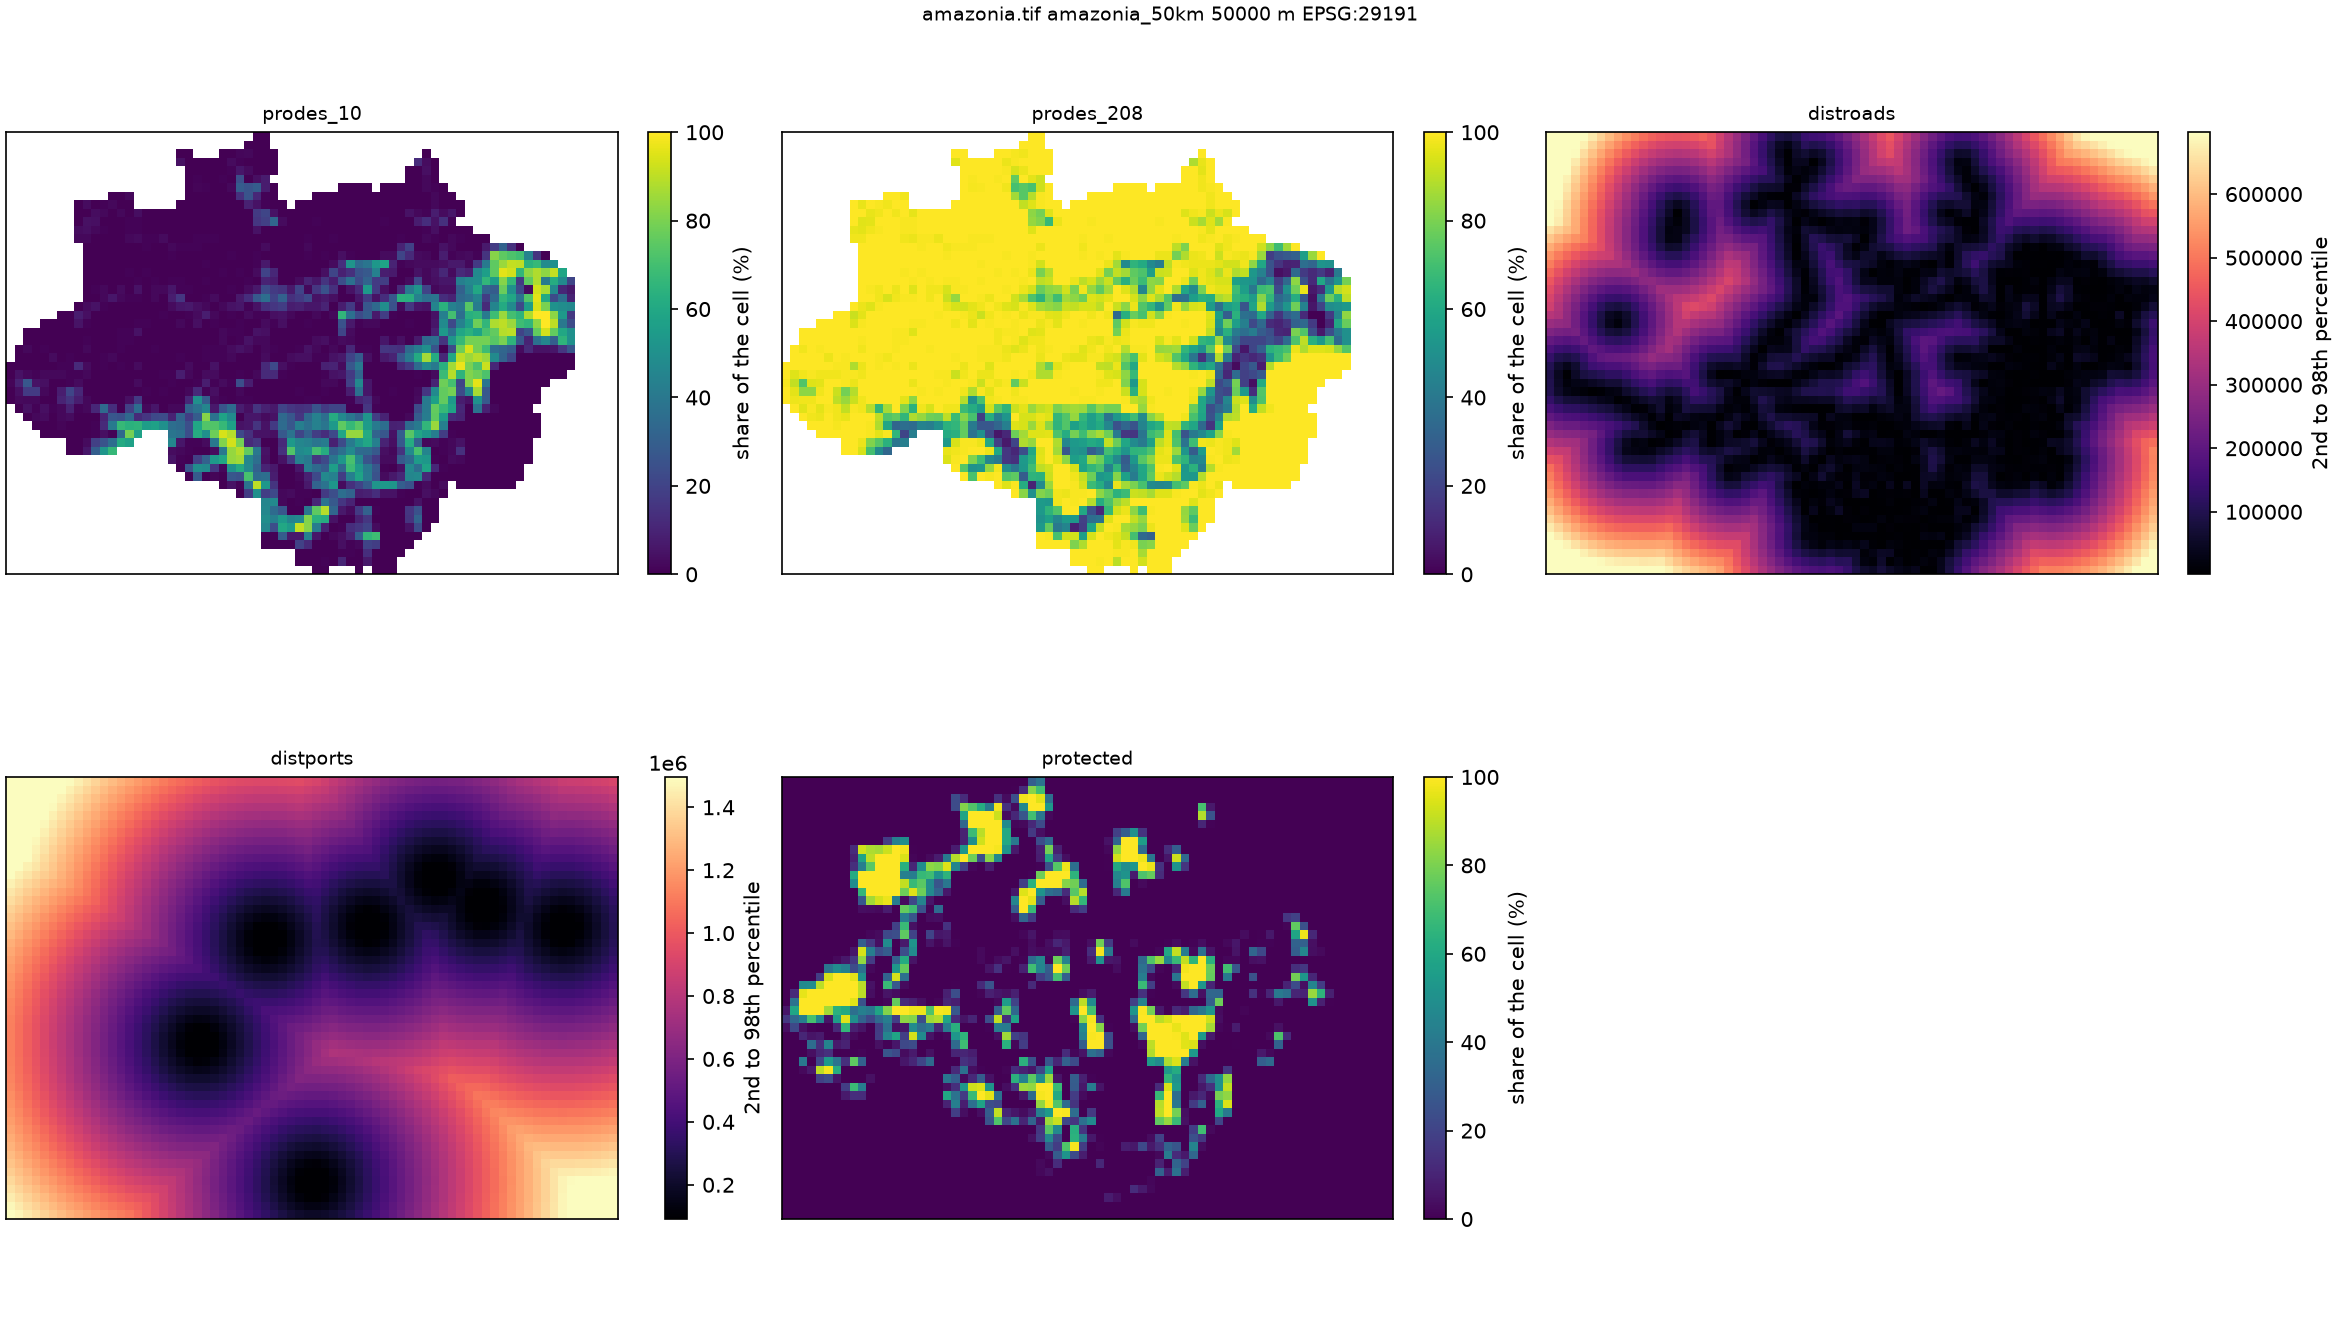

In [8]:
disscube("export", "amazonia.toml", "--workspace", "cubo", "-o", "amazonia.tif")
disscube("plot", "amazonia.tif", "--crop", "-o", "amazonia.png")
%matplotlib inline
# a linha acima devolve os gráficos ao notebook: o `plot` do DisSCube desenha direto em arquivo
Image("amazonia.png", width=900)

✏️ **Pergunta 2.** As duas variáveis de distância têm valor no retângulo todo, inclusive fora da Amazônia; as do PRODES só têm valor onde há dado. Por quê? Isso é um problema para o modelo?

## 4. O registro da execução

Cada `run` grava um registro em `cubo/run.json`: a versão do DisSCube, o hash do arquivo TOML, o hash de cada fonte baixada e, para cada variável, o `spec_hash`, uma impressão digital da especificação (fonte, grade, operador). É o mesmo papel do registro de execução do DisSModel no encontro 4.

In [9]:
registro = json.loads(Path("cubo/run.json").read_text())
print("DisSCube", registro["disscube"], "| TOML", registro["pipeline"]["checksum"][:19] + "…")
pd.DataFrame([{"variável": d["target"], "fonte": d["source"], "spec_hash": d["spec_hash"][:12] + "…"}
              for d in registro["derived"]])

DisSCube 0.6.0 | TOML sha256:c091098f7297…


,variável,fonte,spec_hash
0,prodes_10,prodes,24f18aca6eac…
1,prodes_208,prodes,591508ddc2a7…
2,distroads,roads,74909ac592fe…
3,distports,ports,782e782e0dd0…
4,protected,indigenous,0cd3cbe8c6de…


Rodando de novo, o DisSCube encontra cada `spec_hash` já calculado e não refaz nada:

In [10]:
inicio = time.perf_counter()
disscube("run", "amazonia.toml", "--workspace", "cubo")
print(f"\nsegunda vez: {time.perf_counter() - inicio:.1f} s")

workspace : cubo
derived   : 5 products on amazonia_50km
record    : cubo/run.json

segunda vez: 0.1 s


Se a especificação muda, o hash muda e a variável é recalculada. Fazemos uma cópia do arquivo com células de 100 km:

In [11]:
RESOLUCAO = 100000    # 🔧 metros; experimente 25000

Path("amazonia_grossa.toml").write_text(
    texto.replace('name = "amazonia_50km"', f'name = "amazonia_{RESOLUCAO // 1000}km"')
         .replace("resolution = 50000", f"resolution = {RESOLUCAO}"))
disscube("run", "amazonia_grossa.toml", "--workspace", "cubo")

outro = json.loads(Path("cubo/run.json").read_text())
pd.DataFrame({"50 km": [d["spec_hash"][:12] for d in registro["derived"]],
              f"{RESOLUCAO // 1000} km": [d["spec_hash"][:12] for d in outro["derived"]]},
             index=[d["target"] for d in registro["derived"]])

workspace : cubo
derived   : 5 products on amazonia_100km
record    : cubo/run.json


,50 km,100 km
prodes_10,24f18aca6eac,7def11788853
prodes_208,591508ddc2a7,3cdb135ed24d
distroads,74909ac592fe,87aa623840da
distports,782e782e0dd0,5df1d0dcdff3
protected,0cd3cbe8c6de,0a9e6f725905


✏️ **Pergunta 3.** Uma colega diz que usou "a fração desmatada do PRODES por célula". Com o `run.json` dela em mãos, o que você consegue saber que essa frase não diz?

## 5. Conferir com o TerraME

O `luccme-goldens` guarda o espaço celular que o próprio TerraME produziu com esses dados e essa grade (2.229 células: o TerraME só criou células dentro do limite da Amazônia Legal). Casamos as células pelo centro e medimos a diferença:

In [12]:
ref = pd.read_csv(baixar(
    "https://raw.githubusercontent.com/LambdaGeo/luccme-goldens/v1.1.0/goldens/fill/amazonia_terrame.csv",
    "2203306cfd68b6c43fc6d06dc0cfc6ee3e9445e6e8e00fc476b56b07255620fa",
    "amazonia_terrame.csv"))

cubo = CubeClient("cubo/catalog.db", "cubo/store")
GRADE = "amazonia_50km"
lin = np.floor((ymax - ref["cy"].to_numpy()) / grade["resolution"]).astype(int)   # a linha 0 é a do norte
col = np.floor((ref["cx"].to_numpy() - xmin) / grade["resolution"]).astype(int)

linhas_tabela = []
for var, tolerancia, unidade in [("prodes_10", 0.01, "fração"), ("prodes_208", 0.01, "fração"),
                                 ("protected", 0.01, "fração"), ("distports", 1, "m"), ("distroads", 100, "m")]:
    nosso = cubo.load(var, grid_id=GRADE).to_numpy()[lin, col]
    deles = ref[var].to_numpy()
    ok = ~np.isnan(nosso) & ~np.isnan(deles)
    erro = np.abs(nosso[ok] - deles[ok])
    linhas_tabela.append({"variável": var, "unidade": unidade, "células": ok.sum(),
                          "erro médio": erro.mean(), "erro máximo": erro.max(),
                          f"dentro da tolerância": f"{(erro <= tolerancia).mean():.1%} (≤ {tolerancia} {unidade})"})
pd.DataFrame(linhas_tabela).set_index("variável")

,unidade,células,erro médio,erro máximo,dentro da tolerância
variável,,,,,
prodes_10,fração,2174,6.743306e-13,4.747475e-11,100.0% (≤ 0.01 fração)
prodes_208,fração,2174,1.122292e-12,4.848488e-11,100.0% (≤ 0.01 fração)
protected,fração,2229,1.748488e-05,4.334622e-03,100.0% (≤ 0.01 fração)
distports,m,2229,3.738425e-05,4.964467e-04,100.0% (≤ 1 m)
distroads,m,2229,3.004874e+02,1.810093e+04,79.2% (≤ 100 m)


Quatro variáveis são praticamente iguais. A distância às rodovias difere em média 300 m, chegando a 18 km numa célula, e sempre para menos. A causa está documentada no `disscube-benchmark`: o TerraME mede a distância até o **vértice** mais próximo da linha, e o DisSCube até o **segmento**. Quando a rodovia passa entre dois vértices distantes, o segmento está mais perto do que qualquer vértice:

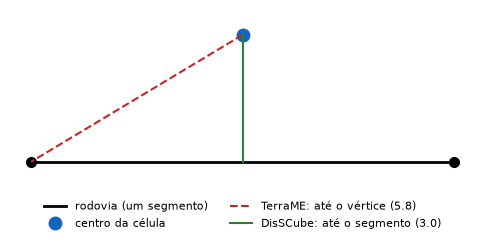

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot([0, 10], [0, 0], "k-", lw=2, label="rodovia (um segmento)")
ax.plot([0, 10], [0, 0], "ko", ms=7)
ax.plot(5, 3, "o", color="#1565c0", ms=9, label="centro da célula")
ax.plot([5, 0], [3, 0], "--", color="#c62828", label=f"TerraME: até o vértice ({np.hypot(5, 3):.1f})")
ax.plot([5, 5], [3, 0], "-", color="#2e7d32", label="DisSCube: até o segmento (3.0)")
ax.set_aspect("equal"); ax.set_ylim(-0.6, 3.6); ax.axis("off")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False);

✏️ **Pergunta 4.** Qual das duas medidas você usaria no seu projeto? E se fosse reproduzir um estudo feito no TerraME?

## 6. Da grade para o modelo

O cubo vai para o DisSModel como um `RasterBackend`, o mesmo objeto em que o encontro 9 colocou as colunas do Acre com `grade.set(...)`. Aqui ele já vem com a projeção e a posição de cada célula:

In [14]:
backend = cubo.to_raster_backend(["prodes_10", "prodes_208", "distroads", "distports", "protected"], grid_id=GRADE)
mascara = ~np.isnan(backend.get("prodes_10"))          # células com dado, como a banda mask do encontro 9
backend.set("mask", mascara.astype(np.float32))
print("bandas:", list(backend.arrays))
print("projeção:", backend.crs, "| células com dado:", int(mascara.sum()), "de", mascara.size)

bandas: ['prodes_10', 'prodes_208', 'distroads', 'distports', 'protected', 'mask']
projeção: EPSG:29191 | células com dado: 2174 de 3744


Com a grade pronta, já dá para olhar a relação que o potencial do encontro 9 supunha: o desmatamento cai com a distância às rodovias?

,fração média em corte raso
"(0, 25]",0.281
"(25, 50]",0.161
"(50, 100]",0.054
"(100, 200]",0.018
"(200, 400]",0.007
"(400, 2000]",0.015


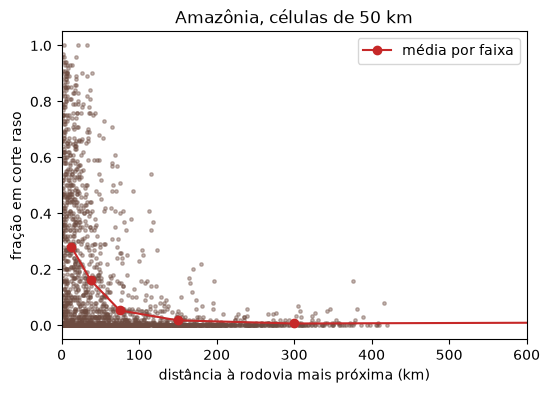

In [15]:
desmatado = backend.get("prodes_10")[mascara]
distancia = backend.get("distroads")[mascara] / 1000

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(distancia, desmatado, s=6, alpha=0.4, color="#6d4c41")
faixas = pd.cut(distancia, [0, 25, 50, 100, 200, 400, 2000])
media = pd.Series(desmatado).groupby(faixas, observed=True).mean()
ax.plot([i.mid for i in media.index], media.values, "o-", color="#c62828", label="média por faixa")
ax.set(xlabel="distância à rodovia mais próxima (km)", ylabel="fração em corte raso", xlim=(0, 600),
       title="Amazônia, células de 50 km"); ax.legend()
media.round(3).to_frame("fração média em corte raso")

O encontro 11 transforma essa nuvem de pontos em coeficientes: ajusta a regressão que o lab01 já trazia pronta.

## Para casa: a grade do seu projeto

1. Copie o modelo abaixo para um arquivo `projeto.toml`, troque o retângulo pela sua área (longitude e latitude: oeste, sul, leste, norte) e escolha o tamanho da célula. Rode `disscube validate projeto.toml` e, se passar, `disscube run projeto.toml --workspace cubo_projeto`. Ele lê o MapBiomas (coleção 11, 30 m) pela internet; uma área de município, com células de 500 m, leva de segundos a poucos minutos.

```toml
schema = 1
name = "Meu projeto"

[grid]
name = "projeto_500m"
bbox = [-44.35, -2.62, -44.20, -2.47]   # oeste, sul, leste, norte (graus); troque pela sua área
resolution = 500                        # metros

[[source]]
id = "uso_{year}"
type = "mapbiomas"
years = [2008, 2024]
collection = 11
resolution = 30

[[derive]]
target = "floresta"
source = "uso_{year}"
operator = "percentage"
class_code = 3          # MapBiomas: formação florestal

[[derive]]
target = "pastagem"
source = "uso_{year}"
operator = "percentage"
class_code = 15         # MapBiomas: pastagem
```

2. Acrescente um `[[derive]]` para um driver do seu projeto que venha de uma camada sua (rodovias, sedes, unidades de conservação), com uma fonte `type = "file"` como as do `amazonia.toml`.
3. Quem não tiver área própria usa um dos casos do repositório `disscube-grids` v1.1.0 (DOI 10.5281/zenodo.23502247), por exemplo `cases/br163/bdc_mapbiomas.toml`.
4. Traga para o encontro 11 a figura do `disscube plot` e o `run.json`.